In [1]:
from os import chdir
from os.path import abspath
thepath = abspath("../base")
chdir(thepath)

In [2]:
# yaml processing file loading. 
import yaml
import numpy as np
import matplotlib.pyplot as plt

from stl import mesh
import pyvista as pv

# for the maximum spanning tree clearance method
from iterative_section_minimiser import mesh_intersect
from geometry import to2D

C:\Users\tangr\AppData\Roaming\Python\Python310\site-packages\matplotlib\projections\__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Read the conduit mapping. 

In [3]:
with open(f"../notebooks/conduit_map.yaml", "r") as f: 
    conduit_map = yaml.safe_load(f)
    f.close()

In [4]:
conduit_map

{1: 'straight_cyl',
 2: 'straight_elp',
 3: 'wavy',
 4: 'rough',
 5: 'sinu_1',
 6: 'sinu_2',
 7: 'branching',
 8: 'archamps',
 9: 'motiers',
 10: 'faux_monnayeurs'}

In [5]:
with open(f"../notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

In [6]:
skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
ct_1_kwargs = p["ct1_kwargs"]
ct_2_kwargs = p["ct2_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]
section_node_kwargs = p["section_node_kwargs"]

In [7]:
# massive pyvista figure with all the meshes. 

# list all meshes. 
list_meshes = []
list_meshes_fp = []
for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    mesh_fp = f"../data/{conduit_id}_{conduit_name}/{conduit_name}.stl"
    list_meshes.append(mesh.Mesh.from_file(mesh_fp))
    list_meshes_fp.append(mesh_fp)

In [8]:
shifts = np.zeros((10,3))
shifts[:,0] = np.linspace(-20, 20, 10)
scales = [1.25,1.25,1.25,1,2,2.5,2.5, 5, 5, 8]

In [9]:
# pl = pv.Plotter(shape=(4,3), image_scale=2, window_size=(1200,1600), border_width=0)
# # Top row
# k = 0
# for i in range(0, 4):
#     for j in range(0, 3):
#         if k < 10:
#             ID = k+1 
#             CONDUIT_NAME = conduit_map[ID]

#             with open(f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
#                 process_p = yaml.safe_load(f)
#                 f.close()
#             pl.subplot(i, j)
            
#             mesh_fp = list_meshes_fp[k]
#             themesh = pv.read(file_format="stl", filename=mesh_fp)
#             _ = pl.add_mesh(themesh, color = "lightblue", opacity = 0.5)
#             pl.add_bounding_box()
#             #actor = pl.show_bounds(location='outer',all_edges=True, grid=None)
        
#             axes = pv.AxesAssembly(position=process_p["axesPosition"], label_size = 2, scale=scales[k])
#             _ = pl.add_actor(axes)
#             actor = pl.add_title(CONDUIT_NAME, font='arial', color='k', font_size=12)


#             k+=1

# pl.save_graphic(f"../temp/figures/summary_all_conduits.pdf")
# # Render all of them
# pl.show()


In [10]:
# list all lbc centrelines, the sources and the target points
list_lbc_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    lbc_ct_fp = f"../temp/{conduit_id}_{conduit_name}/lbc/{conduit_name}_centreline.txt"

    lbc_ct = np.loadtxt(lbc_ct_fp)
    print(lbc_ct_fp)
    
    print(np.mean(lbc_ct, axis = 0)) 
    P1 = lbc_ct[0]
    P2 = lbc_ct[-1]

    list_lbc_ct.append((lbc_ct, P1, P2))

../temp/1_straight_cyl/lbc/straight_cyl_centreline.txt
[-0.09023493 -0.00130173 -0.00120165]
../temp/2_straight_elp/lbc/straight_elp_centreline.txt
[-0.03981244 -0.00026305 -0.00048091]
../temp/3_wavy/lbc/wavy_centreline.txt
[ 0.06889285 -0.04639907 -0.04813331]
../temp/4_rough/lbc/rough_centreline.txt
[-0.13884362 -0.05456385 -0.0313172 ]
../temp/5_sinu_1/lbc/sinu_1_centreline.txt
[-0.03800332  0.02957563 -0.00301788]
../temp/6_sinu_2/lbc/sinu_2_centreline.txt
[ 0.02515956  0.03013049 -0.00011734]
../temp/7_branching/lbc/branching_centreline.txt
[-0.12544644  0.05777967  0.00821553]
../temp/8_archamps/lbc/archamps_centreline.txt
[-0.86822356  0.38073797 -0.96644295]
../temp/9_motiers/lbc/motiers_centreline.txt
[ 0.70410549 -0.61561894 -0.31817571]
../temp/10_faux_monnayeurs/lbc/faux_monnayeurs_centreline.txt
[-0.61690222  0.02522373 -1.52811853]


In [11]:
section_ids = {
    1:[10],
    2:[10],
    3:[6],
    4:[5],
    5:[7],
    6:[7,20],
    7:[7,15],
    8:[15, 30],
    9:[15, 30],
    10:[15, 30]
}

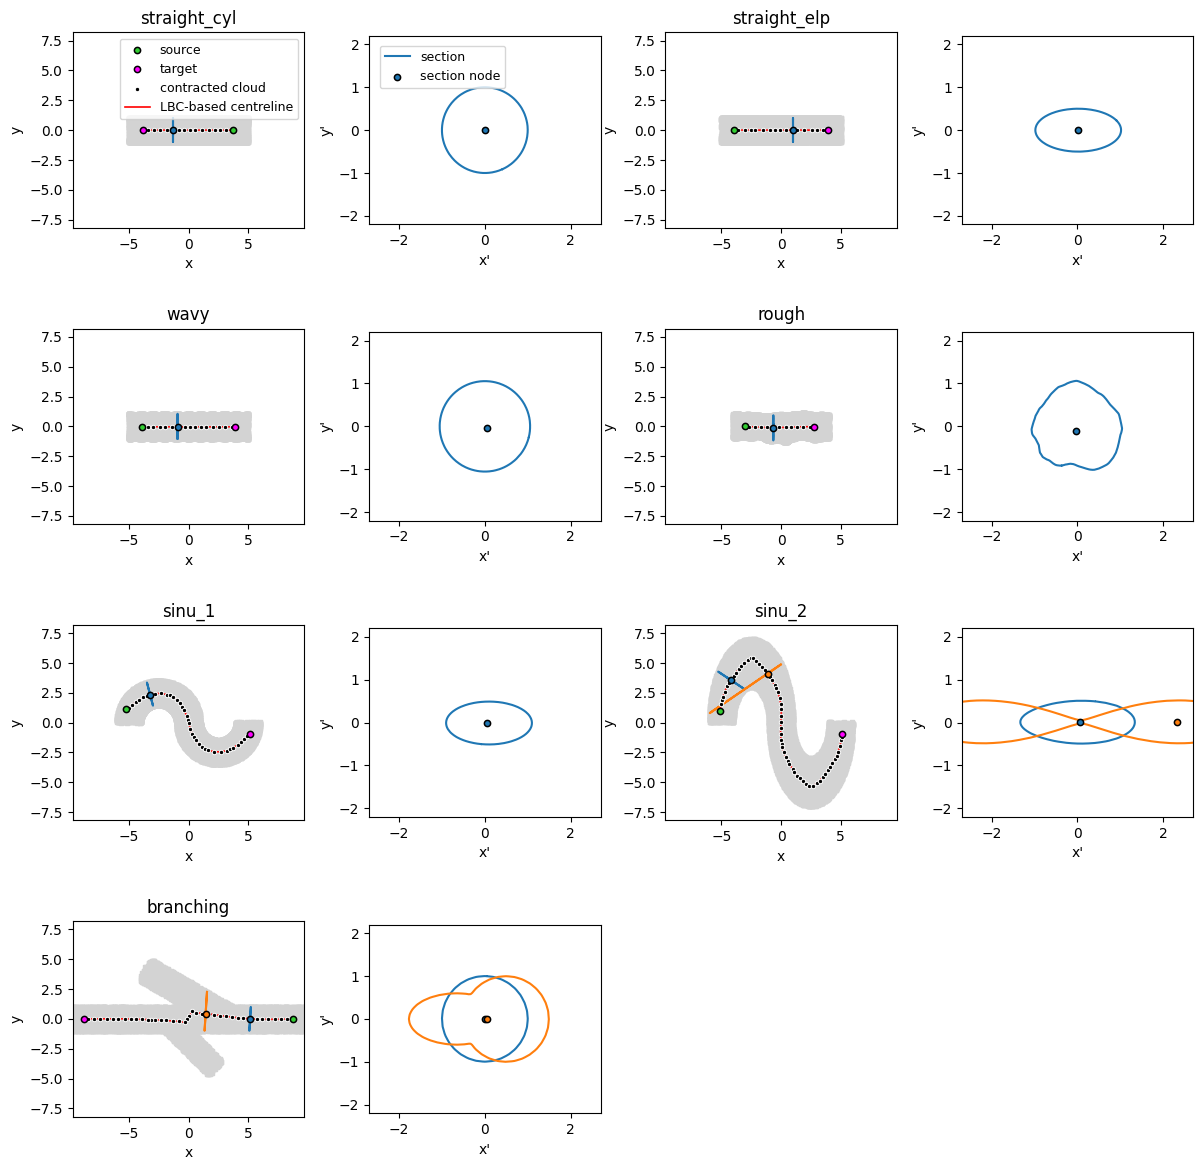

In [17]:
fig, axes = plt.subplots(4,4, figsize=(12,12))

for k, (lbc, P1, P2) in enumerate(list_lbc_ct):
    if k < 7:
        ax = axes.flatten()[2*k]
        ax.scatter(*P1[[0, 1]], **start_kwargs)
        ax.scatter(*P2[[0, 1]], **end_kwargs)
        ax.scatter(*lbc[:,[0, 1]].T, **node_kwargs,label = "contracted cloud")
        ax.plot(*lbc[:,[0, 1]].T, **ct_kwargs, label = "LBC-based centreline")
        ax.set_title(conduit_map[k+1])
        if k == 0:  
            ax.legend(fontsize=9)


for k, themesh in enumerate(list_meshes):
    if k < 7:
        ax= axes.flatten()[2*k]

        ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
        ax.set_aspect("equal")
        ax.set_xlim(-9.7, 9.7)
        ax.set_ylim(-8.2, 8.2)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    # plot a section only. or several. 

for k, (themesh, (lbc, P1, P2)) in enumerate(zip(list_meshes,list_lbc_ct)):
    if k < 7:
        ax = axes.flatten()[2*k]

        ax2 = axes.flatten()[2*k+1]
        thesections = section_ids[k+1]
        for thesection in thesections:
            sectionvec = lbc[thesection+1] - lbc[thesection-1]
            intersect = mesh_intersect(themesh, lbc[thesection], sectionvec)
            polyline3d = intersect[0]
            ax.plot(*polyline3d[:, [0, 1]].T)
            ax.scatter(*lbc[thesection][[0,1]].T,  **section_node_kwargs)

            section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
            ax2.plot(*section2d.T, label = "section")

            rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
            rotinit = R2 @ R1 @ lbc[thesection]
            #print(rotdiff, rotinit, rotinit - rotdiff)
            ax2.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)
            ax2.set_aspect(True)
            if k == 0:
                ax2.legend(fontsize=9, loc = "upper left", bbox_to_anchor=(0.02, 0.98))

        ax2.set_xlim(-2.7, 2.7)
        ax2.set_ylim(-2.2, 2.2)
        ax2.set_xlabel("x'")
        ax2.set_ylabel("y'")


for ax in axes[-1,[-2,-1]]:
    for spine in ["top", "bottom", "left", "right"]:
        ax.spines[spine].set_visible(False)
        ax.set_xticks([])
        ax.set_yticks([])    

plt.tight_layout()
plt.savefig("../temp/figures/summary_synthetic_LBC.png", dpi=300)
plt.savefig("../temp/figures/summary_synthetic_LBC.pdf")
plt.show()


### real caves. 

sections:  [15, 30]
sections:  [15, 30]
sections:  [15, 30]


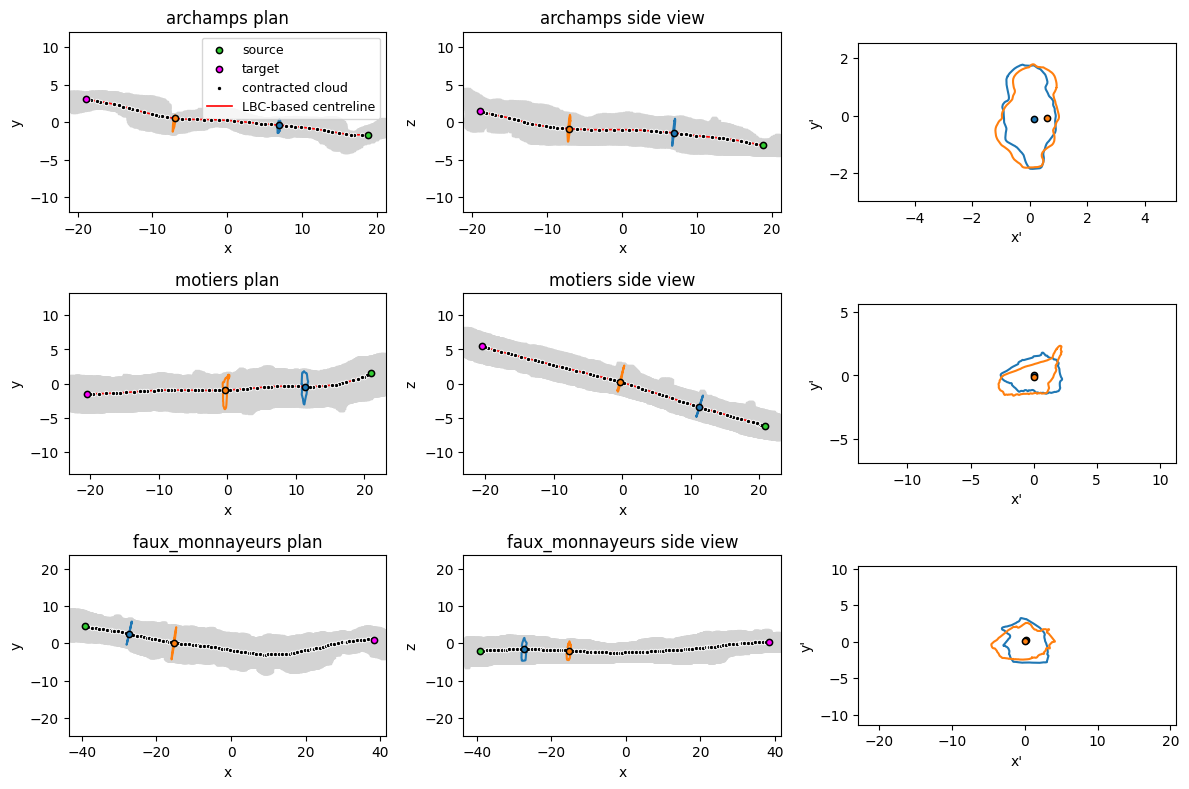

In [ ]:
fig, axes = plt.subplots(3,3, figsize=(12,8))

for k, (lbc, P1, P2) in enumerate(list_lbc_ct):
    if k >= 7:
        k1 = k-7
        ax = axes.flatten()[3*k1]
        ax.scatter(*P1[[0, 1]], **start_kwargs)
        ax.scatter(*P2[[0, 1]], **end_kwargs)
        ax.scatter(*lbc[:,[0, 1]].T, **node_kwargs,label = "contracted cloud")
        ax.plot(*lbc[:,[0, 1]].T, **ct_kwargs, label = "LBC-based centreline")
        ax.set_title(f"{conduit_map[k+1]} plan")
        if k1 == 0:  
            ax.legend(fontsize=9)
        
        ax2 = axes.flatten()[3*k1+1]
        ax2.scatter(*P1[[0, 2]], **start_kwargs)
        ax2.scatter(*P2[[0, 2]], **end_kwargs)
        ax2.scatter(*lbc[:,[0, 2]].T, **node_kwargs,label = "contracted cloud")
        ax2.plot(*lbc[:,[0, 2]].T, **ct_kwargs, label = "LBC-based centreline")
        ax2.set_title(f"{conduit_map[k+1]} side view")


for k, themesh in enumerate(list_meshes):
    if k >= 7:
        k1= k-7
        ax= axes.flatten()[3*k1]

        ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
        ax.set_aspect("equal")
        xmin = np.min(themesh[:, 0])
        xmax = np.max(themesh[:, 0])
        ax.set_xlim(1.02*xmin,1.02*xmax)
        ax.set_ylim(0.58*xmin,0.58*xmax)
        ax.set_xlabel("x")
        ax.set_ylabel("y")

        ax2= axes.flatten()[3*k1+1]

        ax2.scatter(*themesh[::50, [0,2]].T, **mesh_kwargs)
        ax2.set_aspect("equal")
        xmin = np.min(themesh[:, 0])
        xmax = np.max(themesh[:, 0])
        ax2.set_xlim(1.02*xmin,1.02*xmax)
        ax2.set_ylim(0.58*xmin,0.58*xmax)
        ax2.set_xlabel("x")
        ax2.set_ylabel("z")


    # plot a section only. or several. 

for k, (themesh, (lbc, P1, P2)) in enumerate(zip(list_meshes,list_lbc_ct)):
    if k >= 7:
        k1 = k-7
        ax = axes.flatten()[3*k1]
        ax2 = axes.flatten()[3*k1+1]
        ax3 = axes.flatten()[3*k1+2]
        thesections = section_ids[k+1]
        print("sections: ", thesections)
        
        x2min = 0 
        x2max = 0
        for thesection in thesections:
            sectionvec = lbc[thesection+1] - lbc[thesection-1]
            intersect = mesh_intersect(themesh, lbc[thesection], sectionvec)
            polyline3d = intersect[0]
            ax.plot(*polyline3d[:, [0, 1]].T)
            ax.scatter(*lbc[thesection][[0,1]].T,  **section_node_kwargs)
            ax2.plot(*polyline3d[:, [0, 2]].T)
            ax2.scatter(*lbc[thesection][[0,2]].T,  **section_node_kwargs)

            section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
            ax3.plot(*section2d.T, label = "section")

            rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
            rotinit = R2 @ R1 @ lbc[thesection]
            #print(rotdiff, rotinit, rotinit - rotdiff)
            ax3.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)
            ax3.set_aspect(True)
            if k == 0:
                ax3.legend(fontsize=9, loc = "lower left", bbox_to_anchor=(0.02, 1.02))

            ## update the bounds. 
            x2min_n, x2max_n = np.min(section2d[:, 0]), np.max(section2d[:, 0])
            if x2min_n < x2min:
                x2min = x2min_n.copy()


            if x2max_n > x2max:
                x2max = x2max_n.copy()

        ax3.set_xlim(5*x2min,5*x2max)
        ax3.set_ylim(2.5*x2min,2.5*x2max)
        ax3.set_xlabel("x'")
        ax3.set_ylabel("y'")
        

        

plt.tight_layout()
plt.savefig("../temp/figures/summary_real_LBC.png", dpi=300)
plt.savefig("../temp/figures/summary_real_LBC.pdf")

plt.show()


## Minimum spanning tree centrelines.

In [32]:
# list all lbc centrelines, the sources and the target points
list_mst_ct = []
for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    delta = 200
    if k >= 7:
        # real conduits have a different delta, because larger files. 
        delta = 400
    
    mst_ct_fp = f"../temp/{conduit_id}_{conduit_name}/mst/{conduit_name}_{delta}_centerspline-simplified.txt"
    
    try: 
        mst_ct = np.loadtxt(mst_ct_fp)
    except FileNotFoundError:
        mst_ct = np.loadtxt(f"../temp/{conduit_id}_{conduit_name}/mst/{conduit_name}_{delta}_centerspline-direct.txt")
    print(mst_ct_fp)
    print(np.mean(mst_ct, axis = 0)) 
    P1 = mst_ct[0]
    P2 = mst_ct[-1]

    list_mst_ct.append((mst_ct, P1, P2))

../temp/1_straight_cyl/mst/straight_cyl_200_centerspline-simplified.txt
[1.69176842e-17 0.00000000e+00 0.00000000e+00]
../temp/2_straight_elp/mst/straight_elp_200_centerspline-simplified.txt
[-1.20846724e-04 -8.70592438e-05  6.03798274e-05]
../temp/3_wavy/mst/wavy_200_centerspline-simplified.txt
[-1.5719972e-17  0.0000000e+00  0.0000000e+00]
../temp/4_rough/mst/rough_200_centerspline-simplified.txt
[-1.42547154e-16  0.00000000e+00  0.00000000e+00]
../temp/5_sinu_1/mst/sinu_1_200_centerspline-simplified.txt
[ 0.0269902  -0.04690141  0.00010738]
../temp/6_sinu_2/mst/sinu_2_200_centerspline-simplified.txt
[ 0.00230343  0.00187851 -0.00070072]
../temp/7_branching/mst/branching_200_centerspline-simplified.txt
[1.76898606e-16 0.00000000e+00 0.00000000e+00]
../temp/8_archamps/mst/archamps_400_centerspline-simplified.txt
[-0.43434125  0.29453431 -0.99768039]
../temp/9_motiers/mst/motiers_400_centerspline-simplified.txt
[ 0.17760951 -0.17912363 -0.2694887 ]
../temp/10_faux_monnayeurs/mst/faux_m

In [33]:
section_ids_mst = {
    1:[50],
    2:[50],
    3:[50],
    4:[50],
    5:[37],
    6:[37],
    7:[37],
    8:[250, 500],
    9:[250, 500],
    10:[250, 500]
}

[1. 0. 0.]
[-1.00000000e+00 -1.35114098e-05  9.37107658e-06]
[1. 0. 0.]
[1. 0. 0.]
[0.8153251  0.57900345 0.        ]
[0.37840966 0.92563603 0.00201529]
[1. 0. 0.]


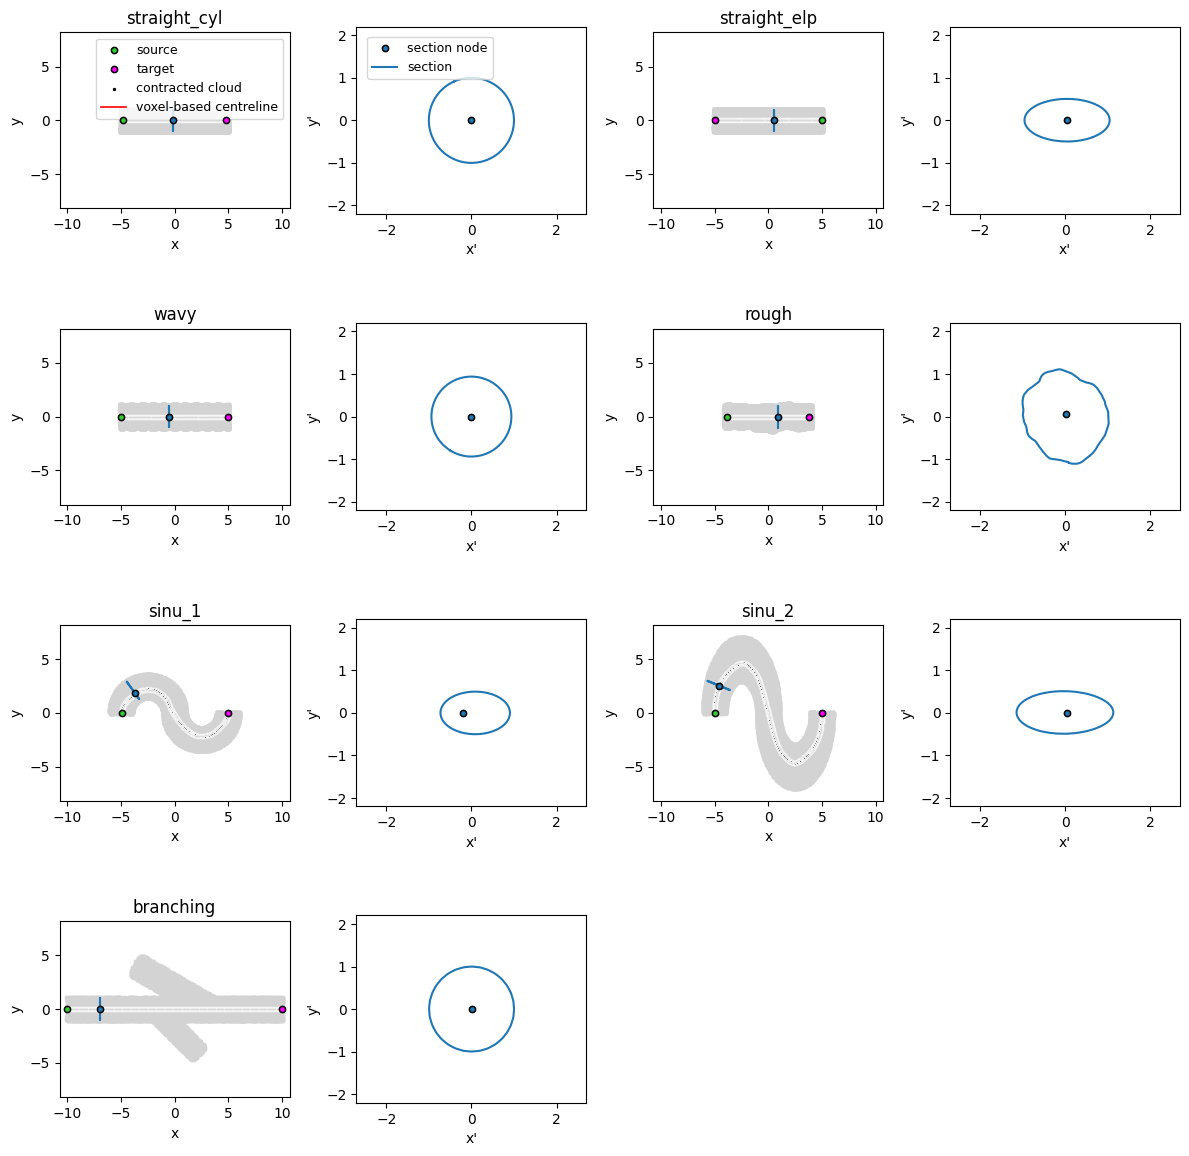

In [34]:
fig, axes = plt.subplots(4,4, figsize=(12,12))

for k, (mst, P1, P2) in enumerate(list_mst_ct):
    if k < 7:
        ax = axes.flatten()[2*k]
        ax.scatter(*P1[[0, 1]], **start_kwargs)
        ax.scatter(*P2[[0, 1]], **end_kwargs)
        ax.scatter(*mst[:,[0, 1]].T, **node_kwargs,label = "contracted cloud")
        ax.plot(*mst[:,[0, 1]].T, **ct_kwargs, label = "voxel-based centreline")
        ax.set_title(conduit_map[k+1])
        if k == 0:  
            ax.legend(fontsize=9)


for k, themesh in enumerate(list_meshes):
    if k < 7:
        ax= axes.flatten()[2*k]

        ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
        ax.set_aspect("equal")
        ax.set_xlim(-10.7, 10.7)
        ax.set_ylim(-8.2, 8.2)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    # plot a section only. or several. 

for k, (themesh, (mst, P1, P2)) in enumerate(zip(list_meshes,list_mst_ct)):
    if k < 7:
        ax = axes.flatten()[2*k]

        ax2 = axes.flatten()[2*k+1]
        thesections = section_ids_mst[k+1]
        for thesection in thesections:
            sectionvec = mst[thesection+1] - mst[thesection-1]
            sectionvec /= np.linalg.norm(sectionvec)
            print(sectionvec)
            intersect = mesh_intersect(themesh, mst[thesection], sectionvec)
            polyline3d = intersect[0]
            ax.plot(*(polyline3d[:, [0, 1]]).T)
            ax.scatter(*mst[thesection][[0,1]].T,  **section_node_kwargs)
            if k<= 4:
                section2d = (polyline3d - np.mean(polyline3d, axis=0))[:, [1,2]]
                ax2.scatter(*(mst[thesection]- np.mean(polyline3d, axis=0))[[1,2]], **section_node_kwargs)
            else:
                section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
            

                rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
                rotinit = R2 @ R1 @ mst[thesection]
                ax2.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)

            #print(rotdiff, rotinit, rotinit - rotdiff)
        
            ax2.plot(*section2d.T, label = "section")

            ax2.set_aspect(True)
            if k == 0:
                ax2.legend(fontsize=9, loc = "upper left", bbox_to_anchor=(0.02, 0.98))

        ax2.set_xlim(-2.7, 2.7)
        ax2.set_ylim(-2.2, 2.2)
        ax2.set_xlabel("x'")
        ax2.set_ylabel("y'")


for ax in axes[-1,[-2,-1]]:
    for spine in ["top", "bottom", "left", "right"]:
        ax.spines[spine].set_visible(False)
        ax.set_xticks([])
        ax.set_yticks([])
        
plt.tight_layout()
plt.savefig("../temp/figures/summary_synthetic_MST.png", dpi=300)
plt.savefig("../temp/figures/summary_synthetic_MST.pdf")

plt.show()


### real caves

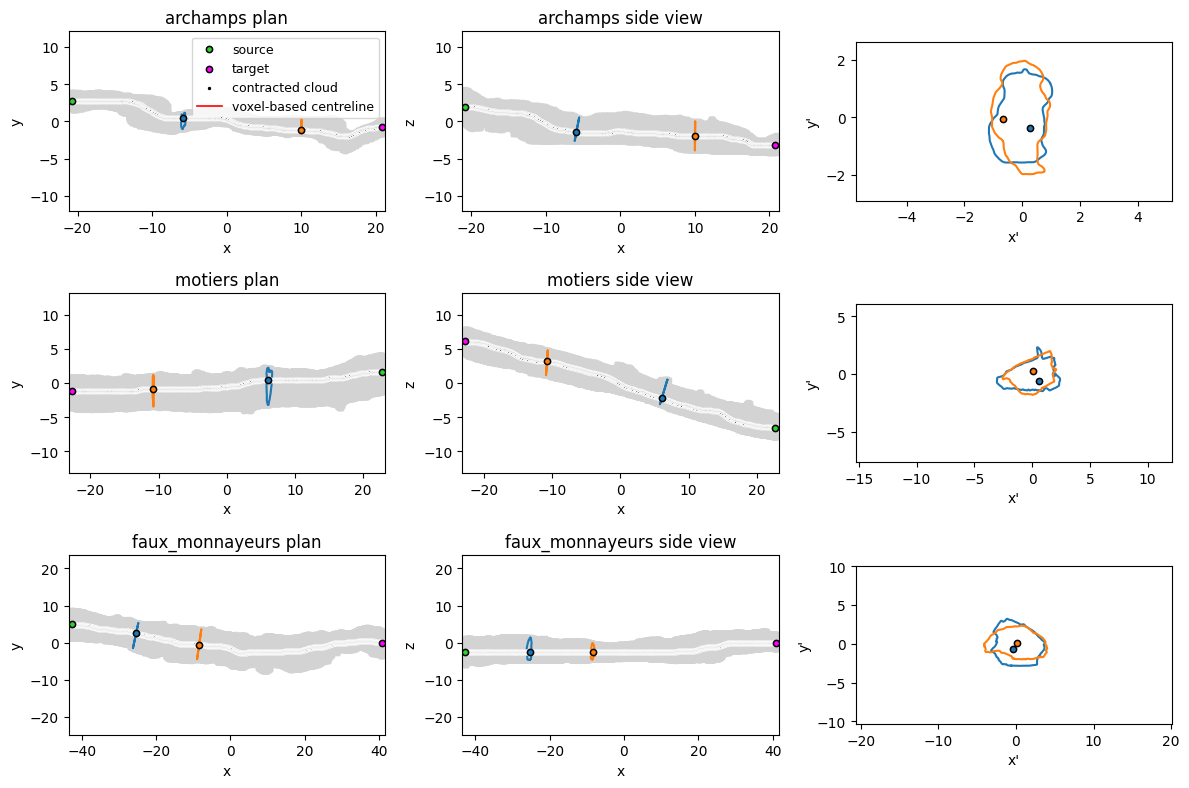

In [35]:
fig, axes = plt.subplots(3,3, figsize=(12,8))

for k, (mst, P1, P2) in enumerate(list_mst_ct):
    if k >= 7:
        k1 = k-7
        ax = axes.flatten()[3*k1]
        ax.scatter(*P1[[0, 1]], **start_kwargs)
        ax.scatter(*P2[[0, 1]], **end_kwargs)
        ax.scatter(*mst[:,[0, 1]].T, **node_kwargs,label = "contracted cloud")
        ax.plot(*mst[:,[0, 1]].T, **ct_kwargs, label = "voxel-based centreline")
        ax.set_title(f"{conduit_map[k+1]} plan")
        if k1 == 0:  
            ax.legend(fontsize=9)
        
        ax2 = axes.flatten()[3*k1+1]
        ax2.scatter(*P1[[0, 2]], **start_kwargs)
        ax2.scatter(*P2[[0, 2]], **end_kwargs)
        ax2.scatter(*mst[:,[0, 2]].T, **node_kwargs,label = "contracted cloud")
        ax2.plot(*mst[:,[0, 2]].T, **ct_kwargs, label = "voxel-based centreline")
        ax2.set_title(f"{conduit_map[k+1]} side view")


for k, themesh in enumerate(list_meshes):
    if k >= 7:
        k1= k-7
        ax= axes.flatten()[3*k1]

        ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
        ax.set_aspect("equal")
        xmin = np.min(themesh[:, 0])
        xmax = np.max(themesh[:, 0])
        ax.set_xlim(1.02*xmin,1.02*xmax)
        ax.set_ylim(0.58*xmin,0.58*xmax)
        ax.set_xlabel("x")
        ax.set_ylabel("y")

        ax2= axes.flatten()[3*k1+1]

        ax2.scatter(*themesh[::50, [0,2]].T, **mesh_kwargs)
        ax2.set_aspect("equal")
        xmin = np.min(themesh[:, 0])
        xmax = np.max(themesh[:, 0])
        ax2.set_xlim(1.02*xmin,1.02*xmax)
        ax2.set_ylim(0.58*xmin,0.58*xmax)
        ax2.set_xlabel("x")
        ax2.set_ylabel("z")


    # plot a section only. or several. 

for k, (themesh, (mst, P1, P2)) in enumerate(zip(list_meshes,list_mst_ct)):
    if k >= 7:
        k1 = k-7
        ax = axes.flatten()[3*k1]
        ax2 = axes.flatten()[3*k1+1]
        ax3 = axes.flatten()[3*k1+2]
        thesections = section_ids_mst[k+1]
        
        
        x2min = 0 
        x2max = 0
        for thesection in thesections:
            sectionvec = mst[thesection+1] - mst[thesection-1]
            intersect = mesh_intersect(themesh, mst[thesection], sectionvec)
            polyline3d = intersect[0]
            ax.plot(*polyline3d[:, [0, 1]].T)
            ax.scatter(*mst[thesection][[0,1]].T,  **section_node_kwargs)
            ax2.plot(*polyline3d[:, [0, 2]].T)
            ax2.scatter(*mst[thesection][[0,2]].T,  **section_node_kwargs)

            section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
            ax3.plot(*section2d.T, label = "section")

            rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
            rotinit = R2 @ R1 @ mst[thesection]
            #print(rotdiff, rotinit, rotinit - rotdiff)
            ax3.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)
            ax3.set_aspect(True)
            if k == 0:
                ax3.legend(fontsize=9, loc = "lower left", bbox_to_anchor=(0.02, 1.02))

            ## update the bounds. 
            x2min_n, x2max_n = np.min(section2d[:, 0]), np.max(section2d[:, 0])
            if x2min_n < x2min:
                x2min = x2min_n.copy()


            if x2max_n > x2max:
                x2max = x2max_n.copy()

        ax3.set_xlim(5*x2min,5*x2max)
        ax3.set_ylim(2.5*x2min,2.5*x2max)
        ax3.set_xlabel("x'")
        ax3.set_ylabel("y'")

        

plt.tight_layout()
plt.savefig("../temp/figures/summary_real_MST.png", dpi=300)
plt.savefig("../temp/figures/summary_real_MST.pdf")
plt.show()


## List all iterative centrelines

In [36]:
# list all iterative centrelines, the sources and the target points
list_iter_ct = []
list_iter_norm = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    iter_ct_fp = f"../temp/{conduit_id}_{conduit_name}/iterative/{conduit_name}_centreline.txt"
    iter_norm_fp = f"../temp/{conduit_id}_{conduit_name}/iterative/{conduit_name}_vectors.txt"

    iter_ct = np.loadtxt(iter_ct_fp)
    iter_norm = np.loadtxt(iter_norm_fp)
    print(iter_ct_fp)
    print(np.mean(iter_ct, axis = 0)) 
    P1 = iter_ct[0]
    P2 = iter_ct[-1]

    list_iter_ct.append((iter_ct, P1, P2))
    list_iter_norm.append(iter_norm)

../temp/1_straight_cyl/iterative/straight_cyl_centreline.txt
[-7.06266235e-03  1.79283696e-04  4.74418630e-06]
../temp/2_straight_elp/iterative/straight_elp_centreline.txt
[-0.00858508  0.00593968 -0.00012244]
../temp/3_wavy/iterative/wavy_centreline.txt
[ 0.00551136 -0.00030335  0.00060712]
../temp/4_rough/iterative/rough_centreline.txt
[-0.19270224 -0.03128033 -0.02749854]
../temp/5_sinu_1/iterative/sinu_1_centreline.txt
[-0.03954616  0.04627652  0.00083878]
../temp/6_sinu_2/iterative/sinu_2_centreline.txt
[ 0.02192664 -0.00668486 -0.00171859]
../temp/7_branching/iterative/branching_centreline.txt
[0.00080753 0.02483459 0.00094908]
../temp/8_archamps/iterative/archamps_centreline.txt
[ 1.2543095   0.19014118 -1.15571151]
../temp/9_motiers/iterative/motiers_centreline.txt
[-0.40189236 -0.60116071 -0.06542034]
../temp/10_faux_monnayeurs/iterative/faux_monnayeurs_centreline.txt
[ 0.34112024 -0.03008052 -1.64151216]


In [ ]:
section_ids_iter = {
    1:[10],
    2:[10],
    3:[10],
    4:[10],
    5:[12],
    6:[6],
    7:[7],
    8:[10, 20],
    9:[10, 30],
    10:[20, 35]
}

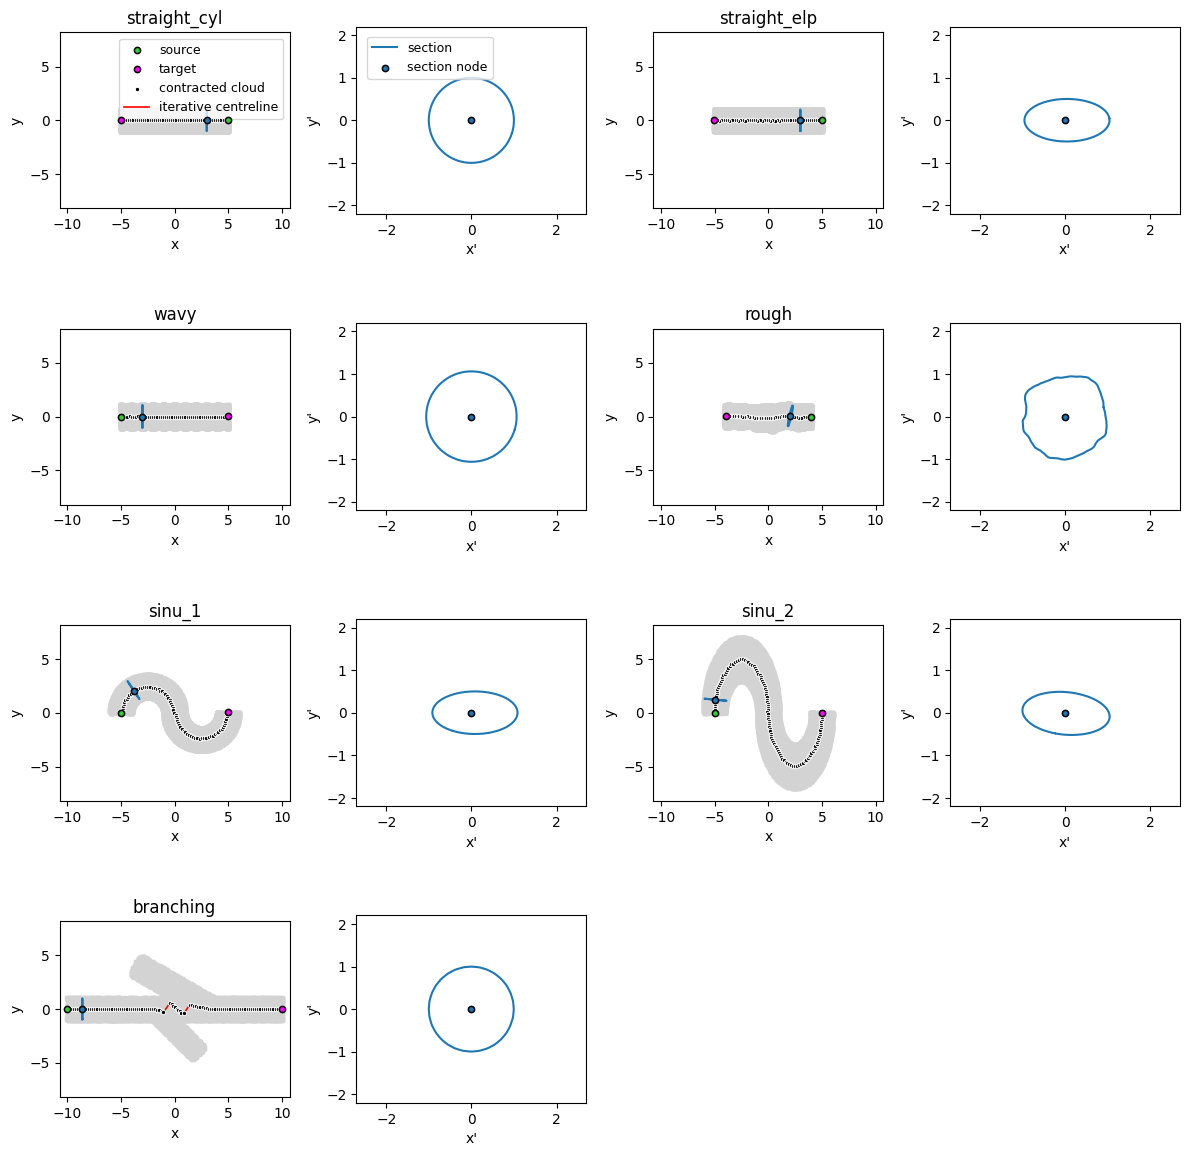

In [38]:
fig, axes = plt.subplots(4,4, figsize=(12,12))

for k, (iter, P1, P2) in enumerate(list_iter_ct):
    if k <7:
        ax = axes.flatten()[2*k]
        ax.scatter(*P1[[0, 1]], **start_kwargs)
        ax.scatter(*P2[[0, 1]], **end_kwargs)
        ax.scatter(*iter[:,[0, 1]].T, **node_kwargs,label = "contracted cloud")
        ax.plot(*iter[:,[0, 1]].T, **ct_kwargs, label = "iterative centreline")
        ax.set_title(conduit_map[k+1])
        if k == 0:  
            ax.legend(fontsize=9)


for k, themesh in enumerate(list_meshes):
    if k < 7:
        ax= axes.flatten()[2*k]

        ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
        ax.set_aspect("equal")
        ax.set_xlim(-10.7, 10.7)
        ax.set_ylim(-8.2, 8.2)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    # plot a section only. or several. 

for k, (themesh, (iter, P1, P2), thenorm) in enumerate(zip(list_meshes,list_iter_ct, list_iter_norm)):
    if k < 7:
        ax = axes.flatten()[2*k]

        ax2 = axes.flatten()[2*k+1]
        thesections = section_ids_iter[k+1]
        for thesection in thesections:
            sectionvec = thenorm[thesection]
            intersect = mesh_intersect(themesh, iter[thesection], sectionvec)
            polyline3d = intersect[0]
            ax.plot(*polyline3d[:, [0, 1]].T)
            ax.scatter(*iter[thesection][[0,1]].T,  **section_node_kwargs)

            section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
            ax2.plot(*section2d.T, label = "section")

            rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
            rotinit = R2 @ R1 @ iter[thesection]
            #print(rotdiff, rotinit, rotinit - rotdiff)
            ax2.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)
            ax2.set_aspect(True)
            if k == 0:
                ax2.legend(fontsize=9, loc = "upper left", bbox_to_anchor=(0.02, 0.98))

        ax2.set_xlim(-2.7, 2.7)
        ax2.set_ylim(-2.2, 2.2)
        ax2.set_xlabel("x'")
        ax2.set_ylabel("y'")


for ax in axes[-1,[-2,-1]]:
    for spine in ["top", "bottom", "left", "right"]:
        ax.spines[spine].set_visible(False)
        ax.set_xticks([])
        ax.set_yticks([])  

plt.tight_layout()
plt.savefig("../temp/figures/summary_synthetic_iterative.png", dpi=300)
plt.savefig("../temp/figures/summary_synthetic_iterative.pdf")

plt.show()


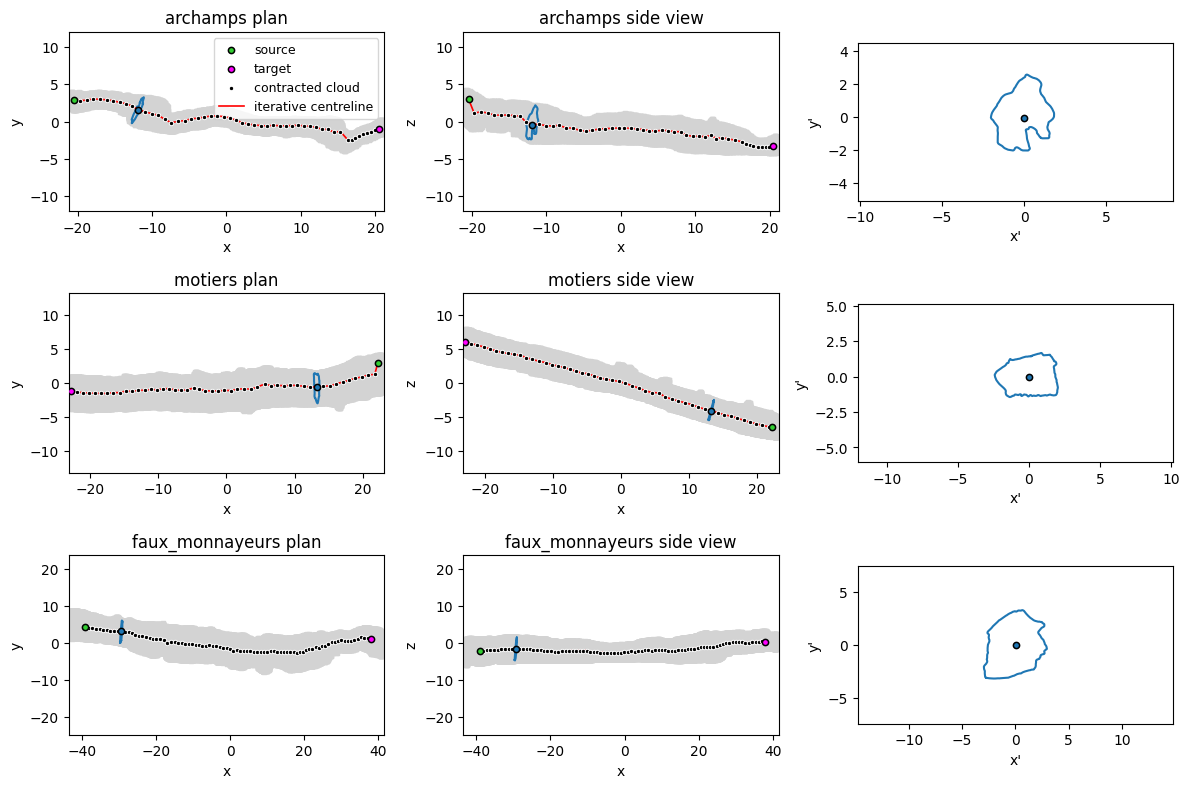

In [39]:
fig, axes = plt.subplots(3,3, figsize=(12,8))

for k, (iter, P1, P2) in enumerate(list_iter_ct):
    if k >= 7:
        k1 = k-7
        ax = axes.flatten()[3*k1]
        ax.scatter(*P1[[0, 1]], **start_kwargs)
        ax.scatter(*P2[[0, 1]], **end_kwargs)
        ax.scatter(*iter[:,[0, 1]].T, **node_kwargs,label = "contracted cloud")
        ax.plot(*iter[:,[0, 1]].T, **ct_kwargs, label = "iterative centreline")
        ax.set_title(f"{conduit_map[k+1]} plan")
        if k1 == 0:  
            ax.legend(fontsize=9)
        
        ax2 = axes.flatten()[3*k1+1]
        ax2.scatter(*P1[[0, 2]], **start_kwargs)
        ax2.scatter(*P2[[0, 2]], **end_kwargs)
        ax2.scatter(*iter[:,[0, 2]].T, **node_kwargs,label = "contracted cloud")
        ax2.plot(*iter[:,[0, 2]].T, **ct_kwargs, label = "iterative centreline")
        ax2.set_title(f"{conduit_map[k+1]} side view")


for k, themesh in enumerate(list_meshes):
    if k >= 7:
        k1= k-7
        ax= axes.flatten()[3*k1]

        ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
        ax.set_aspect("equal")
        xmin = np.min(themesh[:, 0])
        xmax = np.max(themesh[:, 0])
        ax.set_xlim(1.02*xmin,1.02*xmax)
        ax.set_ylim(0.58*xmin,0.58*xmax)
        ax.set_xlabel("x")
        ax.set_ylabel("y")

        ax2= axes.flatten()[3*k1+1]

        ax2.scatter(*themesh[::50, [0,2]].T, **mesh_kwargs)
        ax2.set_aspect("equal")
        xmin = np.min(themesh[:, 0])
        xmax = np.max(themesh[:, 0])
        ax2.set_xlim(1.02*xmin,1.02*xmax)
        ax2.set_ylim(0.58*xmin,0.58*xmax)
        ax2.set_xlabel("x")
        ax2.set_ylabel("z")


    # plot a section only. or several. 

for k, (themesh, (iter, P1, P2)) in enumerate(zip(list_meshes,list_iter_ct)):
    if k >= 7:
        k1 = k-7
        ax = axes.flatten()[3*k1]
        ax2 = axes.flatten()[3*k1+1]
        ax3 = axes.flatten()[3*k1+2]
        thesections = section_ids_iter[k1+1]
        
        
        x2min = 0 
        x2max = 0
        for thesection in thesections:
            sectionvec = iter[thesection+1] - iter[thesection-1]
            intersect = mesh_intersect(themesh, iter[thesection], sectionvec)
            polyline3d = intersect[0]
            ax.plot(*polyline3d[:, [0, 1]].T)
            ax.scatter(*iter[thesection][[0,1]].T,  **section_node_kwargs)
            ax2.plot(*polyline3d[:, [0, 2]].T)
            ax2.scatter(*iter[thesection][[0,2]].T,  **section_node_kwargs)

            section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
            ax3.plot(*section2d.T, label = "section")

            rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
            rotinit = R2 @ R1 @ iter[thesection]
            #print(rotdiff, rotinit, rotinit - rotdiff)
            ax3.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)
            ax3.set_aspect(True)
            if k == 0:
                ax3.legend(fontsize=9, loc = "lower left", bbox_to_anchor=(0.02, 1.02))

            ## update the bounds. 
            x2min_n, x2max_n = np.min(section2d[:, 0]), np.max(section2d[:, 0])
            if x2min_n < x2min:
                x2min = x2min_n.copy()


            if x2max_n > x2max:
                x2max = x2max_n.copy()

        ax3.set_xlim(5*x2min,5*x2max)
        ax3.set_ylim(2.5*x2min,2.5*x2max)
        ax3.set_xlabel("x'")
        ax3.set_ylabel("y'")

        

plt.tight_layout()
plt.savefig("../temp/figures/summary_real_iterative.png", dpi=300)
plt.savefig("../temp/figures/summary_real_iterative.pdf")
plt.show()


In [28]:
## plot the hydraulic centrelines. 
list_hydraulic_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    hydraulic_ct_fp = f"../temp/{conduit_id}_{conduit_name}/hydraulic/{conduit_name}_centreline.csv"
    
    if k < 7:
        hydraulic_ct1 = np.loadtxt(hydraulic_ct_fp, skiprows =1, delimiter=",", usecols=[1,2,3])
        hydraulic_ct2 = np.loadtxt(hydraulic_ct_fp, skiprows =1, delimiter=",", usecols=[4,5,6])

        print(np.mean(hydraulic_ct1, axis = 0)) 
        P1 = hydraulic_ct1[0]
        P2 = hydraulic_ct1[-1]

        list_hydraulic_ct.append((hydraulic_ct1, P1, P2, hydraulic_ct2))

[2.95480924e+00 8.00681420e-03 2.90633592e-03]
[ 2.65497683e+00  9.70891375e-03 -1.94721556e-03]
[ 2.19628172e+00  1.13544066e-03 -8.28149526e-03]
[ 2.06843727 -0.0816778   0.07815049]
[ 2.37782626 -0.07545599 -0.00245678]
[ 2.63400769e+00 -9.68886205e-02  2.42350830e-03]
[ 7.36419867e+00 -2.90669471e-04  2.03056452e-03]


In [29]:
section_ids_hydraulic = {
    1:[1000],
    2:[1000],
    3:[1000],
    4:[1000],
    5:[3200],
    6:[3600],
    7:[5000,13000]
}

[ 1.00000000e+00 -9.57592339e-06  2.73597811e-05]
[ 9.99999999e-01  1.41843972e-05 -3.12056737e-05]
[ 9.99999859e-01 -1.45939066e-04 -5.10152212e-04]
[ 0.99399087 -0.05789472  0.09289973]
[ 4.26028569e-01 -9.04709652e-01  3.22406496e-04]
[ 3.15112288e-01 -9.49054359e-01 -2.62411344e-04]
[ 9.99999876e-01 -4.97872279e-04  0.00000000e+00]
[ 9.99950163e-01 -9.97806647e-03 -3.32244963e-04]


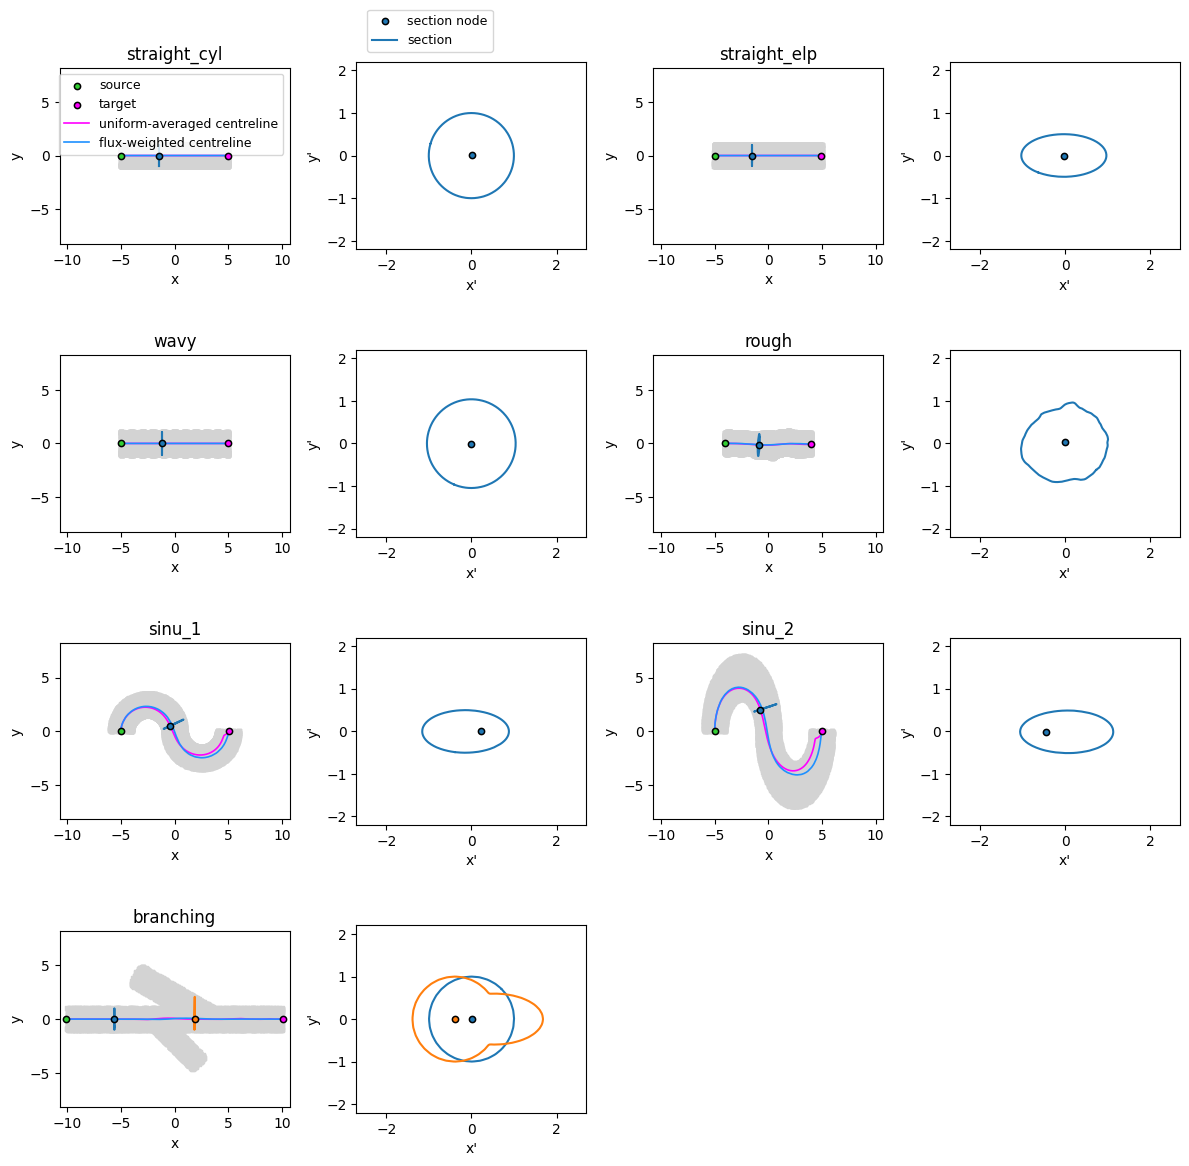

In [31]:
fig, axes = plt.subplots(4,4, figsize=(12,12))

for k, (hydraulic_1, P1, P2, hydraulic_2) in enumerate(list_hydraulic_ct):
    if k < 7:
        ax = axes.flatten()[2*k]
        ax.scatter(*P1[[0, 1]], **start_kwargs)
        ax.scatter(*P2[[0, 1]], **end_kwargs)
        ax.plot(*hydraulic_1[:,[0, 1]].T, **ct_1_kwargs, label = "uniform-averaged centreline")
        ax.plot(*hydraulic_2[:,[0, 1]].T, **ct_2_kwargs, label = "flux-weighted centreline")
        ax.set_title(conduit_map[k+1])
        if k == 0:  
            ax.legend(fontsize=9)


for k, themesh in enumerate(list_meshes):
    if k < 7:
        ax= axes.flatten()[2*k]

        ax.scatter(*themesh[::50, [0,1]].T, **mesh_kwargs)
        ax.set_aspect("equal")
        ax.set_xlim(-10.7, 10.7)
        ax.set_ylim(-8.2, 8.2)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    # plot a section only. or several. 


for k, (themesh, (hydraulic_1, P1, P2, hydraulic_2)) in enumerate(zip(list_meshes,list_hydraulic_ct)):
     if k < 7:
        ax = axes.flatten()[2*k]

        ax2 = axes.flatten()[2*k+1]
        thesections = section_ids_hydraulic[k+1]
        for thesection in thesections:
            sectionvec = hydraulic_1[thesection+1] - hydraulic_1[thesection-1]
            sectionvec /= np.linalg.norm(sectionvec)
            print(sectionvec)
            
            intersect = mesh_intersect(themesh, hydraulic_1[thesection], sectionvec)
            polyline3d = intersect[0]
            ax.plot(*(polyline3d[:, [0, 1]]).T)
            ax.scatter(*hydraulic_1[thesection][[0,1]].T,  **section_node_kwargs)
            if k< 4:
                section2d = (polyline3d - np.mean(polyline3d, axis=0))[:, [1,2]]
                ax2.scatter(*(hydraulic_1[thesection]- np.mean(polyline3d, axis=0))[[1,2]], **section_node_kwargs)
            else:
                section2d, R1, R2 = to2D(polyline3d, sectionvec, returnTransform=True)
            

                rotdiff = R2 @ (R1 @ (np.mean(polyline3d, axis = 0)))
                rotinit = R2 @ R1 @ hydraulic_1[thesection]
                ax2.scatter(*(rotinit - rotdiff)[[0,2]].T,  **section_node_kwargs)

            #print(rotdiff, rotinit, rotinit - rotdiff)
        
            ax2.plot(*section2d.T, label = "section")

            ax2.set_aspect(True)
            if k == 0:
                ax2.legend(fontsize=9, loc = "lower left", bbox_to_anchor=(0.02, 1.02))

            ax2.set_xlim(-2.7, 2.7)
            ax2.set_ylim(-2.2, 2.2)
            ax2.set_xlabel("x'")
            ax2.set_ylabel("y'")

for ax in axes[-1,[-2,-1]]:
    for spine in ["top", "bottom", "left", "right"]:
        ax.spines[spine].set_visible(False)
        ax.set_xticks([])
        ax.set_yticks([])
    
plt.tight_layout()
plt.savefig("../temp/figures/summary_synthetic_hydraulic.png", dpi=300)
plt.savefig("../temp/figures/summary_synthetic_hydraulic.pdf")

plt.show()
